# Experiment: Principal Component Analysis
---



## Objective

- To simplify a dataset by reducing the number of features (dimensions) while preserving as much of the original information (variance) as possible. 
- Finding new, uncorrelated axes (principal components) that align with the directions of maximum variance in the data.



## Setup

Imports and configuration.


In [2]:
# Import libraries

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set aesthetics
sns.set_theme(
    style="whitegrid",
    font="DejaVu Sans",       # clean, readable sans-serif (works cross-platform)
    font_scale=1.1,           # slightly larger text overall
)





## Data
--- 

Load / inspect / prepare the data.

In [3]:
df_wine = load_wine()

X = pd.DataFrame(df_wine.data, columns=df_wine.feature_names)
y = df_wine.target

X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [4]:
# Shape of dataset

print('**Original Data Shape**\n')
print(f"Dataset has {X.shape[0]} samples and {X.shape[1]} features.")

**Original Data Shape**

Dataset has 178 samples and 13 features.


### Preprocessing

In [5]:
# Always Scale the dataset firsrt
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[ 1.51861254, -0.5622498 ,  0.23205254, -1.16959318,  1.91390522,
         0.80899739,  1.03481896, -0.65956311,  1.22488398,  0.25171685,
         0.36217728,  1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, -2.49084714,  0.01814502,
         0.56864766,  0.73362894, -0.82071924, -0.54472099, -0.29332133,
         0.40605066,  1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, -0.2687382 ,  0.08835836,
         0.80899739,  1.21553297, -0.49840699,  2.13596773,  0.26901965,
         0.31830389,  0.78858745,  1.39514818],
       [ 1.69154964, -0.34681064,  0.4879264 , -0.80925118,  0.93091845,
         2.49144552,  1.46652465, -0.98187536,  1.03215473,  1.18606801,
        -0.42754369,  1.18407144,  2.33457383],
       [ 0.29570023,  0.22769377,  1.84040254,  0.45194578,  1.28198515,
         0.80899739,  0.66335127,  0.22679555,  0.40140444, -0.31927553,
         0.36217728,  0.44960118, -0.03787401]])



## Experiment


###  PCA with original dimension

In [6]:
# Fit the PCA 
# Instantiating PCA without constraining components (no decomposition yet)
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

# Calculate variance characteristics
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

print(pca_full.components_.shape)


(13, 13)


In [7]:
explained_variance_ratio

array([0.36198848, 0.1920749 , 0.11123631, 0.0706903 , 0.06563294,
       0.04935823, 0.04238679, 0.02680749, 0.02222153, 0.01930019,
       0.01736836, 0.01298233, 0.00795215])

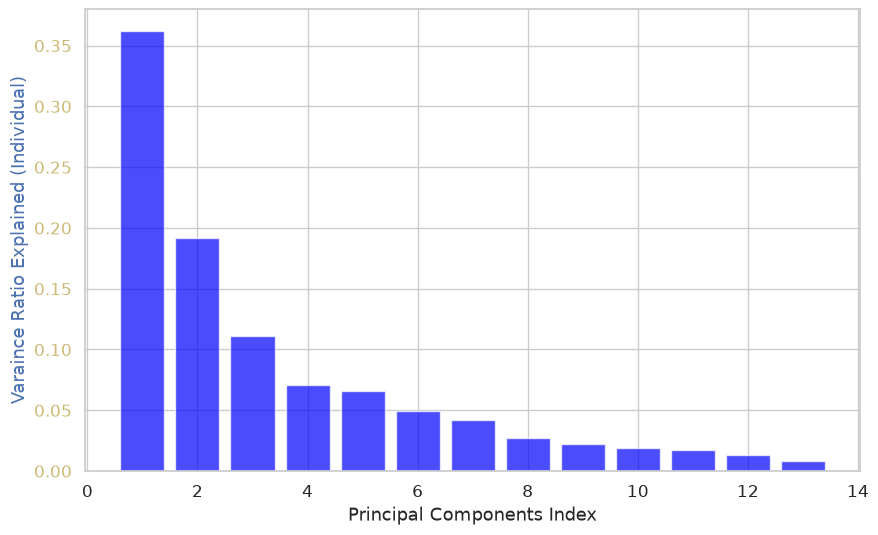

In [8]:
# Visualize Optimal Components

fig, ax1 = plt.subplots(figsize=(10,6))

# Individual variance bar chart

ax1.bar(
    range(1, len(explained_variance_ratio) +1 ),
    explained_variance_ratio,
    alpha=0.7,
    color='blue',
    label='Individual Varaince'

)

ax1.set_xlabel('Principal Components Index')
ax1.set_ylabel('Varaince Ratio Explained (Individual)', color='b')
ax1.tick_params(axis='y', labelcolor='y')

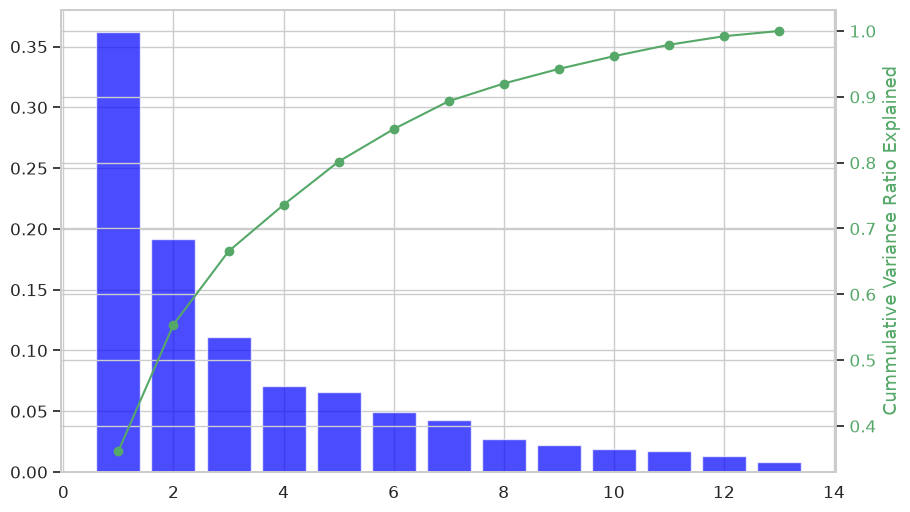

In [9]:
# Cummulative Variance Step Line

fig, ax1 = plt.subplots(figsize=(10,6))

#Individual variance bar chart

ax1.bar(
    range(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio,
    alpha=0.7,
    color='blue',
    label='Individual Variance'
)

ax2 = ax1.twinx()
ax2.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    color='g',
    label='Cumulative Variance'
)

ax2.set_xlabel("Principal Component Index")
ax2.set_ylabel("Cummulative Variance Ratio Explained", color='g')
ax2.tick_params(axis='y', labelcolor='g')

### Choosing the Right Number of Dimensions 

- We compute PCA without reducing dimensionality, then compute the minimum number of dimensions required to preserve 95% of the training set's variance.

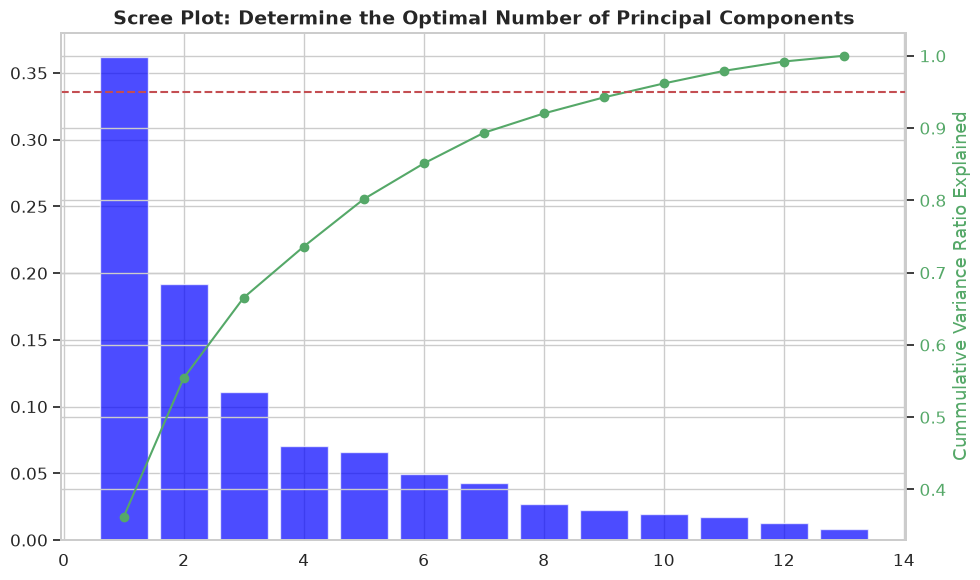

In [ ]:
# Set  the Threshold at 95%

fig, ax1 = plt.subplots(figsize=(10,6))

#Individual variance bar chart

ax1.bar(
    range(1, len(explained_variance_ratio) + 1),
    explained_variance_ratio,
    alpha=0.7,
    color='blue',
    label='Individual Variance'
)

ax2 = ax1.twinx()
ax2.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    color='g',
    label='Cumulative Variance'
)
ax2.set_xlabel("Principal Component Index")
ax2.set_ylabel("Cummulative Variance Ratio Explained", color='g')
ax2.axhline(y=0.95, color='r', linestyle='--', label="95% Varaince Cutoff")
ax2.tick_params(axis='y', labelcolor='g')
plt.title('Scree Plot: Determine the Optimal Number of Principal Components', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

In [11]:
# Find the exact component index that crosses our 95% variance target
optimal_components = np.argmax(cumulative_variance >=0.95) + 1
print(f'—→ {optimal_components} components are needed to preserve 95% total variance')

—→ 10 components are needed to preserve 95% total variance


## Results

Visualizations, metrics, outputs.


In [12]:
# Rerun PCA with the optimal number of components
pca_10d = PCA(n_components=optimal_components, random_state=42)
X_pca_10d = pca_10d.fit_transform(X_scaled)
X_pca_10d

array([[ 3.31675081e+00,  1.44346263e+00, -1.65739045e-01, ...,
        -6.51390947e-02, -6.41442706e-01,  1.02095585e+00],
       [ 2.20946492e+00, -3.33392887e-01, -2.02645737e+00, ...,
        -1.02441595e+00,  3.08846753e-01,  1.59701372e-01],
       [ 2.51674015e+00,  1.03115130e+00,  9.82818670e-01, ...,
         3.44216131e-01,  1.17783447e+00,  1.13360857e-01],
       ...,
       [-2.67783946e+00,  2.76089913e+00, -9.40941877e-01, ...,
        -4.70238043e-02, -1.22214687e-03, -2.47997312e-01],
       [-2.38701709e+00,  2.29734668e+00, -5.50696197e-01, ...,
        -3.90828774e-01, -5.74476725e-02,  4.91489502e-01],
       [-3.20875816e+00,  2.76891957e+00,  1.01391366e+00, ...,
         2.92913734e-01, -7.41660423e-01, -1.17969019e-01]],
      shape=(178, 10))

In [13]:
# Create a clean dataframe with the lower dimension data
pca_columns = [f"PC{i}" for i in range(1, optimal_components + 1)]

df_pca = pd.DataFrame(X_pca_10d, columns=pca_columns)
df_pca.index +=1
df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
1,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956
2,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701
3,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361
4,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413
5,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366


In [14]:
# Join the target variable to df_pca

df_pca['target'] = df_wine['target']

df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,target
1,3.316751,1.443463,-0.165739,-0.215631,0.693043,0.223880,0.596427,-0.065139,-0.641443,1.020956,0
2,2.209465,-0.333393,-2.026457,-0.291358,-0.257655,0.927120,0.053776,-1.024416,0.308847,0.159701,0
3,2.516740,1.031151,0.982819,0.724902,-0.251033,-0.549276,0.424205,0.344216,1.177834,0.113361,0
4,3.757066,2.756372,-0.176192,0.567983,-0.311842,-0.114431,-0.383337,-0.643593,-0.052544,0.239413,0
5,1.008908,0.869831,2.026688,-0.409766,0.298458,0.406520,0.444074,-0.416700,-0.326819,-0.078366,0


In [15]:
df_pca.tail(20)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,target
159,-1.048182,3.515090,1.160039,0.935329,-0.899449,-3.284281,-0.642463,0.522336,-0.943267,0.351884,2
160,-1.609912,2.406638,0.548560,0.754310,-0.995207,-2.919477,-0.711056,-0.137528,-0.189549,0.079947,2
161,-3.143131,0.738161,-0.090999,0.980648,-0.409814,-0.398922,-0.074031,-1.093190,0.155798,-0.621055,2
162,-2.240157,1.175465,-0.101377,-1.165279,-0.264449,0.801039,0.539883,0.132604,-0.555590,-0.246821,2
163,-2.847674,0.556044,0.804215,-0.897888,-0.254801,0.288568,0.867762,-0.251984,-0.318611,0.252622,2
164,-2.597497,0.697966,-0.884940,-0.274229,0.772235,0.719842,0.272500,-0.260542,0.339492,0.224802,2
165,-2.949299,1.555309,-0.983401,0.015480,-0.364082,-0.491206,-0.985935,0.785797,-0.356328,0.007655,2
166,-3.530032,0.882527,-0.466029,0.580790,-0.668960,0.458814,0.522221,1.075128,-0.486439,0.034277,2
167,-2.406111,2.592356,0.428226,-0.184335,0.447661,-0.569506,0.035802,0.673245,-0.168007,-0.865855,2
168,-2.929085,1.274447,-1.213358,0.295316,-0.267350,-0.381213,-0.644321,-0.000553,0.502531,-0.600024,2


### 2D scatter plot

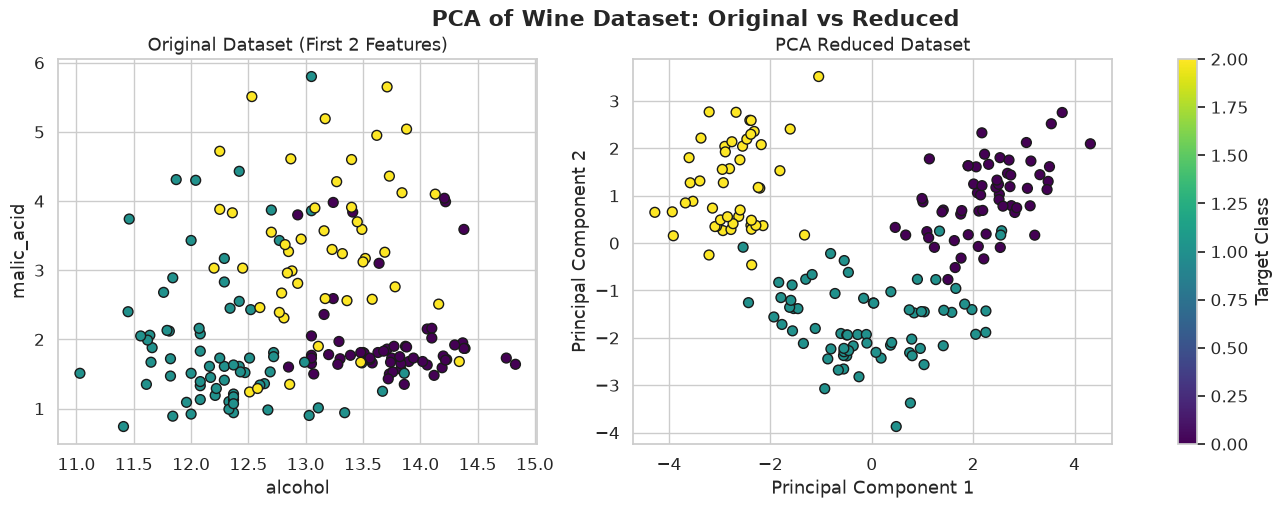

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))

# Left plot: Original features (pick 2 actual feature columns from X)
ax[0].scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
ax[0].set_xlabel(X.columns[0])
ax[0].set_ylabel(X.columns[1])
ax[0].set_title('Original Dataset (First 2 Features)')

# Right plot: PCA reduced
sc = ax[1].scatter(df_pca['PC1'], df_pca['PC2'], c=y, cmap='viridis', edgecolor='k', s=50)
ax[1].set_xlabel('Principal Component 1')
ax[1].set_ylabel('Principal Component 2')
ax[1].set_title('PCA Reduced Dataset')

fig.suptitle('PCA of Wine Dataset: Original vs Reduced', fontsize=16, fontweight='bold')
fig.colorbar(sc, label='Target Class', ax=ax)
plt.show()

We can see the same separation in the reduced dataset, suggesting that the original variance was retained.

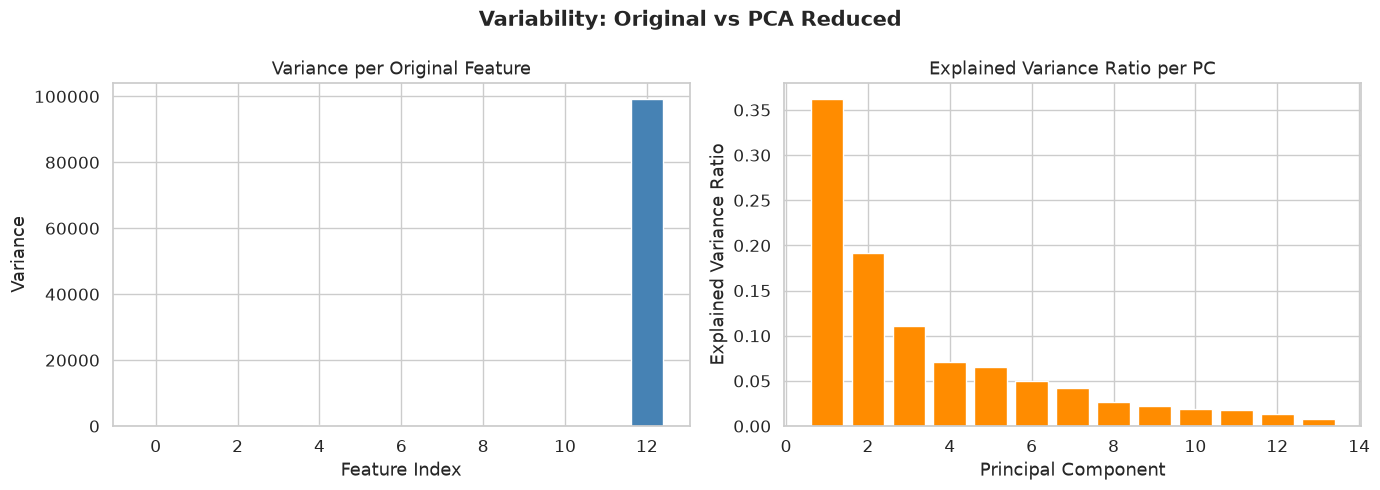

In [17]:
# Explained variance comparison
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Original: variance per feature
ax[0].bar(range(X.shape[1]), X.var(), color='steelblue')
ax[0].set_title('Variance per Original Feature')
ax[0].set_xlabel('Feature Index')
ax[0].set_ylabel('Variance')

# Reduced: explained variance ratio of PCs
ax[1].bar(range(1, len(explained_variance_ratio)+1),
          explained_variance_ratio, color='darkorange')
ax[1].set_title('Explained Variance Ratio per PC')
ax[1].set_xlabel('Principal Component')
ax[1].set_ylabel('Explained Variance Ratio')

fig.suptitle('Variability: Original vs PCA Reduced', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

We can see distinct clusters of different colors, this suggest that PCA successfully reduced the dimensions while keeping the data separable (i.e. preserving the original variance)



## Interpretation

What happened and why?





## Key Takeaways
